
# Geophysical Signal Preprocessing

## GeoWaveAI

This notebook introduces important preprocessing techniques used in geophysical signal processing.

Raw signals may contain unwanted noise, baseline drift, invalid values, and frequency components that make analysis difficult.

We will generate a synthetic geophysical signal and apply different preprocessing techniques to understand how they work.

### Learning Objectives

By completing this notebook, we will learn to:

1. Generate and inspect a synthetic geophysical signal.
2. Understand missing and invalid signal values.
3. Remove the mean from a signal.
4. Remove linear trends using detrending.
5. Normalize signal amplitude.
6. Apply low-pass, high-pass, and band-pass filters.
7. Compare signals before and after filtering.
8. Understand frequency response.
9. Evaluate whether preprocessing preserves a weak signal event.

**Note:** All signals in this notebook are synthetic educational examples. They are not real seismic or DAS recordings.



## 1. Introduction to Geophysical Signal Preprocessing

Signal preprocessing is the process of preparing raw measurements before further analysis.

A recorded geophysical signal may contain several unwanted components.

Examples include:

- Baseline drift: Slow changes in the signal baseline.
- Random noise: Unwanted random variations.
- Electrical interference: Unwanted periodic components.
- Invalid values: Missing or infinite numerical measurements.

These problems can affect later analysis and make weak events more difficult to identify.

Preprocessing helps improve signal quality, but it must be performed carefully.

An important goal in GeoWaveAI is to remove unwanted components without accidentally removing weak microseismic events.


In [1]:

# Import scientific computing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal

print("Libraries imported successfully!")


Libraries imported successfully!



## 2. Generating a Synthetic Geophysical Signal

Before working with real recordings, we will create a synthetic signal.

Our example will contain four components:

1. A weak event that represents a possible geophysical event.
2. Baseline drift that slowly changes the signal.
3. Periodic interference at a higher frequency.
4. Random noise.

We will combine these components to create a raw signal.

Because we generate the signal ourselves, we know which components are useful and which are unwanted.

This makes it easier to understand how preprocessing changes the signal.


In [2]:

# Define sampling information

sampling_rate = 500
duration = 10

number_of_samples = sampling_rate * duration

time = np.arange(number_of_samples) / sampling_rate

# Generate a weak event using a Gaussian envelope

event_center = 5.0
event_width = 0.25
event_frequency = 25

envelope = np.exp(
    -0.5 * ((time - event_center) / event_width) ** 2
)

event_signal = 0.35 * envelope * np.sin(
    2 * np.pi * event_frequency * time
)

# Generate baseline drift

baseline_drift = (
    0.4 * (time / duration)
    + 0.15 * np.sin(2 * np.pi * 0.3 * time)
)

# Generate periodic interference

interference = 0.2 * np.sin(
    2 * np.pi * 60 * time
)

# Generate random noise

np.random.seed(42)

random_noise = np.random.normal(
    0, 0.25, number_of_samples
)

# Combine all components

raw_signal = (
    event_signal
    + baseline_drift
    + interference
    + random_noise
)

print("Synthetic signal generated successfully!")
print("Sampling rate:", sampling_rate, "Hz")
print("Duration:", duration, "seconds")
print("Number of samples:", number_of_samples)


Synthetic signal generated successfully!
Sampling rate: 500 Hz
Duration: 10 seconds
Number of samples: 5000


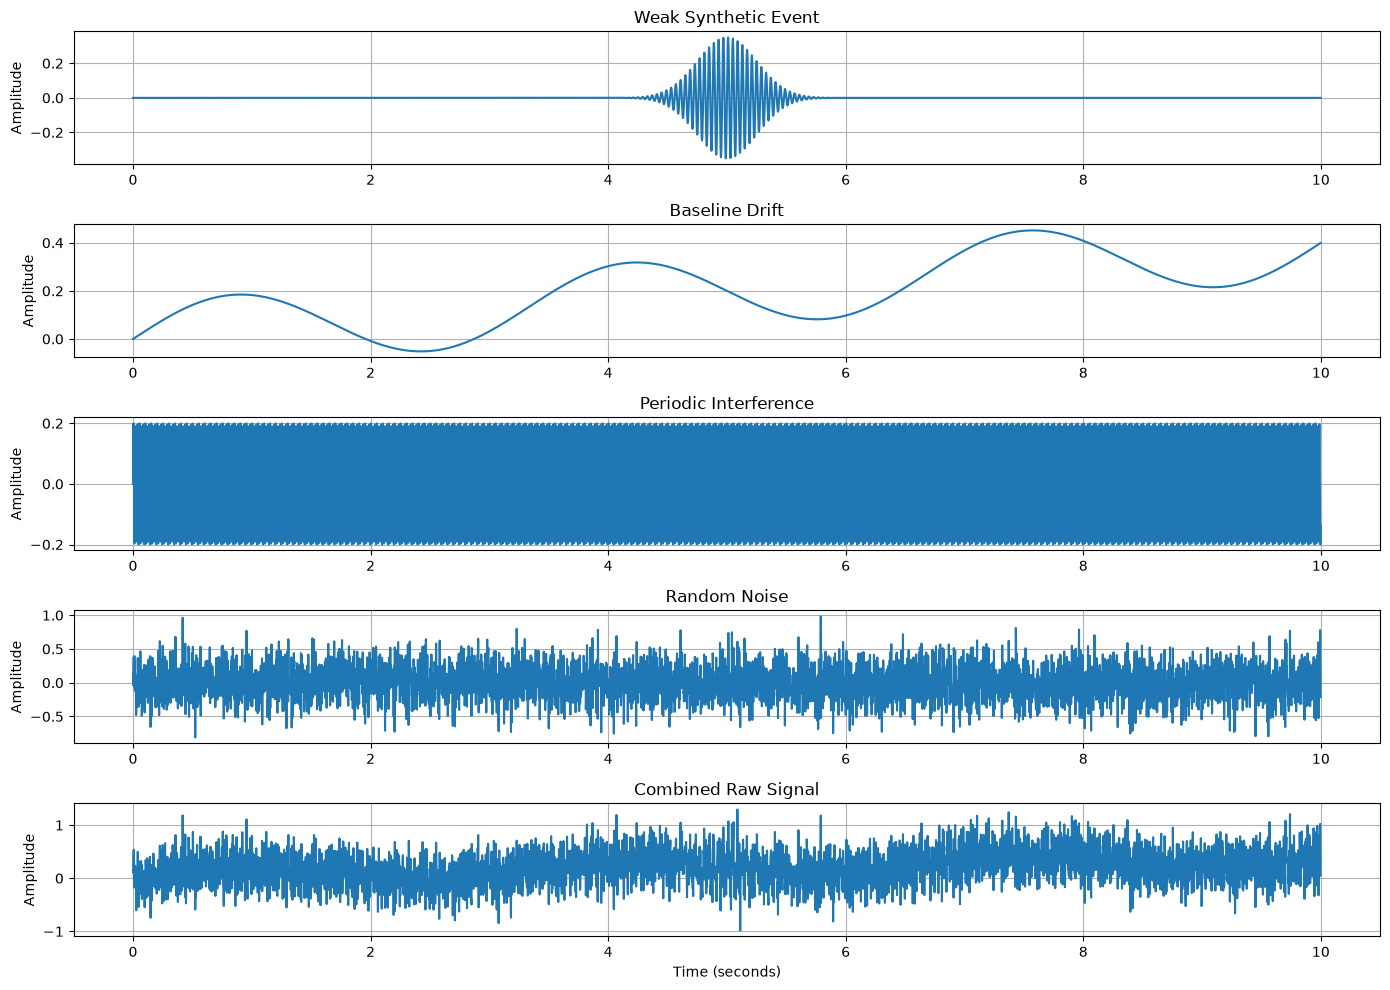

In [3]:

# Visualize the individual components and combined signal

plt.figure(figsize=(14, 10))

plt.subplot(5, 1, 1)
plt.plot(time, event_signal)
plt.title("Weak Synthetic Event")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(5, 1, 2)
plt.plot(time, baseline_drift)
plt.title("Baseline Drift")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(5, 1, 3)
plt.plot(time, interference)
plt.title("Periodic Interference")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(5, 1, 4)
plt.plot(time, random_noise)
plt.title("Random Noise")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(5, 1, 5)
plt.plot(time, raw_signal)
plt.title("Combined Raw Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()



## 3. Handling Missing and Invalid Values

Sometimes a recorded signal may contain missing or invalid numerical values.

Examples include:

- NaN: A value that is not available or not a valid number.
- Positive infinity: An infinitely large positive value.
- Negative infinity: An infinitely large negative value.

These values can cause problems during mathematical calculations and signal processing.

One possible approach is interpolation.

Interpolation estimates missing values using nearby valid measurements.

In this example, we will use linear interpolation to fill internal missing values.

**Important:** Interpolation is not suitable for every situation. Long missing sections or gaps around important events require careful investigation.


In [4]:

# Create a copy of the raw signal for demonstration

signal_with_missing = raw_signal.copy()

# Insert some invalid values

signal_with_missing[100] = np.nan
signal_with_missing[101] = np.nan
signal_with_missing[500] = np.inf
signal_with_missing[501] = -np.inf

# Convert infinite values into NaN

signal_with_missing[
    ~np.isfinite(signal_with_missing)
] = np.nan

print("Missing values before interpolation:",
      np.isnan(signal_with_missing).sum())

# Use linear interpolation

cleaned_series = pd.Series(signal_with_missing).interpolate(
    method="linear"
)

cleaned_signal = cleaned_series.to_numpy()

print("Missing values after interpolation:",
      np.isnan(cleaned_signal).sum())

print("Invalid value handling completed!")


Missing values before interpolation: 4
Missing values after interpolation: 0
Invalid value handling completed!



## 4. Removing the Mean (Demeaning)

The mean is the average value of a signal.

Sometimes a signal has a constant offset, meaning its values are shifted above or below zero.

Demeaning removes this constant offset by subtracting the mean from every sample.

Formula:

Demeaned Signal = Original Signal - Mean

After demeaning, the average value of the resulting signal should be approximately zero.

However, demeaning does not remove a changing baseline or a linear trend.


Original signal mean: 0.20136048252189334
Demeaned signal mean: -1.1368683772161604e-17


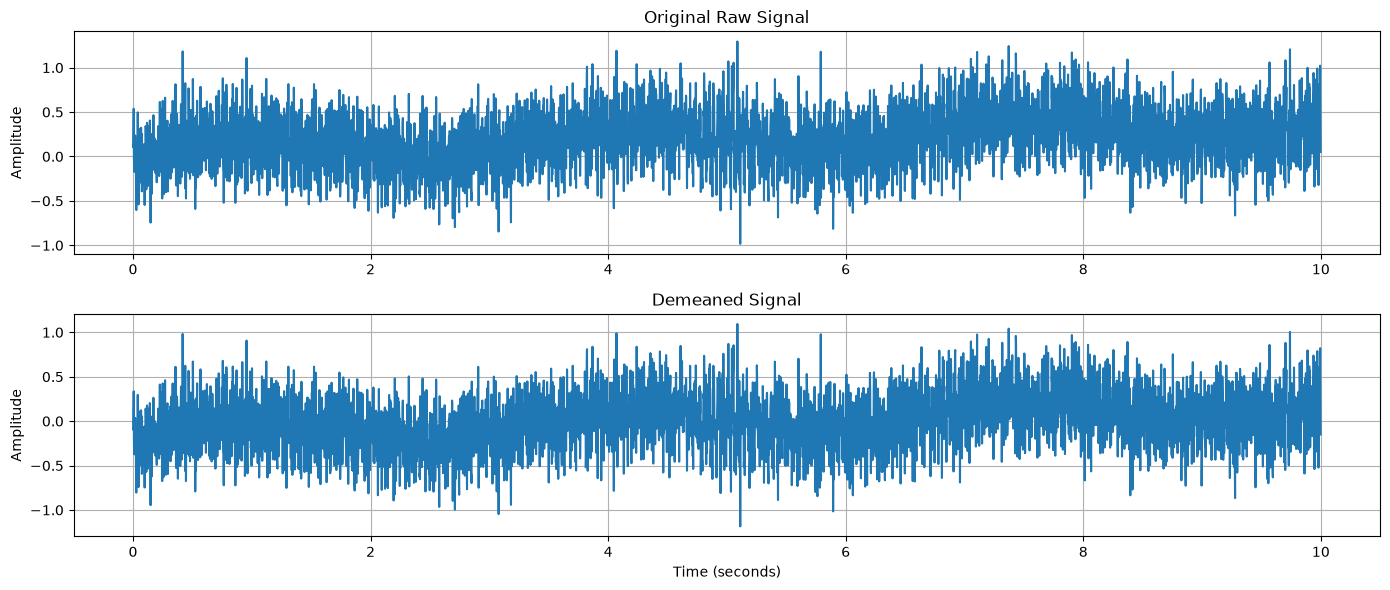

In [5]:

# Calculate the mean of the raw signal

signal_mean = np.mean(raw_signal)

# Remove the mean

demeaned_signal = raw_signal - signal_mean

print("Original signal mean:", signal_mean)
print("Demeaned signal mean:", np.mean(demeaned_signal))

# Compare original and demeaned signals

plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(time, raw_signal)
plt.title("Original Raw Signal")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, demeaned_signal)
plt.title("Demeaned Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()



## 5. Removing Linear Trends (Detrending)

A signal may contain a baseline that gradually increases or decreases over time.

This is called a trend.

Demeaning removes a constant average offset, but it does not necessarily remove a changing linear trend.

Detrending removes a fitted trend from the signal.

For example, linear detrending estimates a straight-line trend and subtracts it from the original signal.

This helps reduce slow linear changes in the baseline.

We will use the SciPy detrend function.

**Important:** Detrending can also change genuine low-frequency information. It should not be applied automatically without considering the signal and research objective.


Detrending completed!


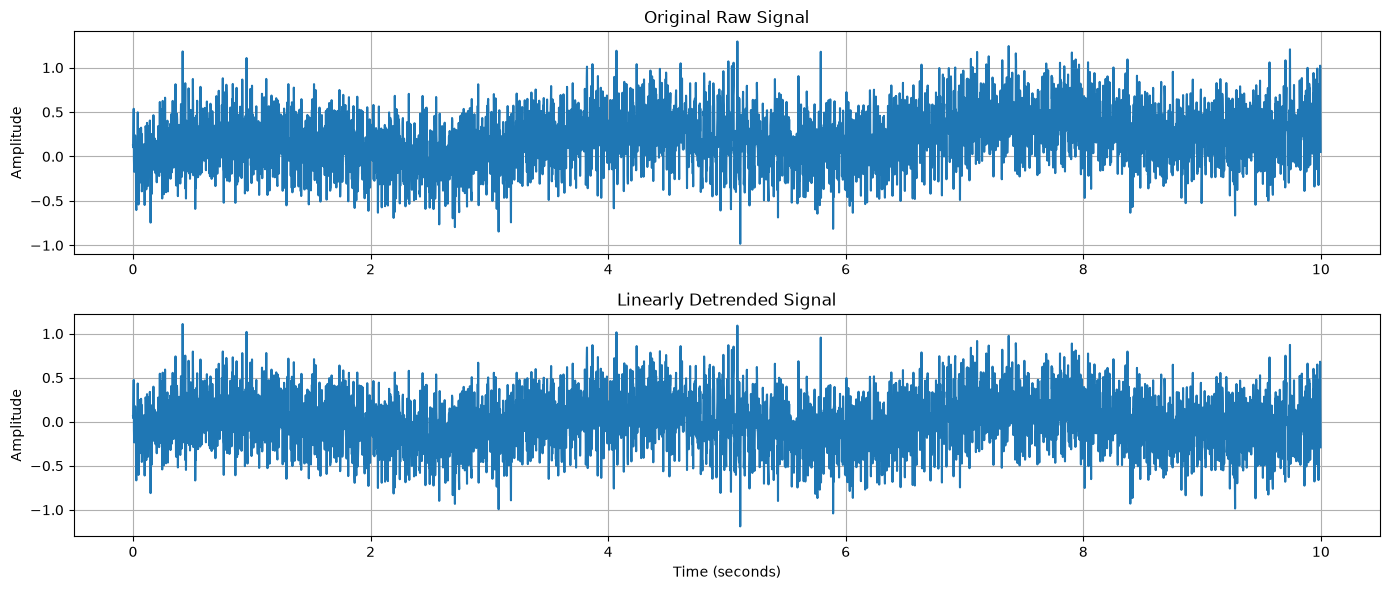

In [6]:

# Remove the linear trend

detrended_signal = signal.detrend(
    raw_signal,
    type="linear"
)

print("Detrending completed!")

# Compare the raw and detrended signals

plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(time, raw_signal)
plt.title("Original Raw Signal")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, detrended_signal)
plt.title("Linearly Detrended Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()



## 6. Signal Normalization

Normalization changes the scale of signal values.

Different signals may have very different amplitude ranges.

Normalization can help make their numerical scales more comparable.

In this notebook, we will use Z-score normalization.

Formula:

Normalized Signal = (Signal - Mean) / Standard Deviation

After Z-score normalization:

- The mean should be approximately zero.
- The standard deviation should be approximately one.

Normalization changes the amplitude scale, but it does not automatically remove noise or unwanted frequency components.

We should also remember that normalization may affect the physical amplitude information of a signal.


Normalized signal mean: -3.979039320256561e-17
Normalized signal standard deviation: 1.0000000000000002


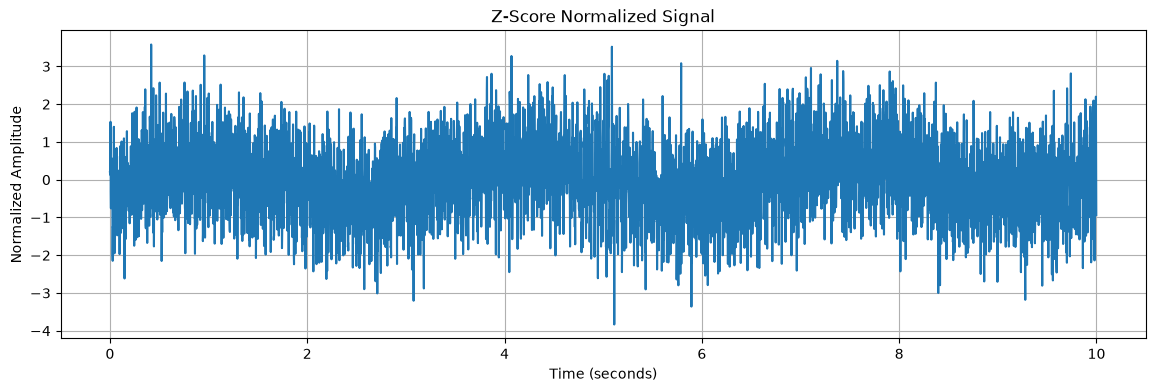

In [7]:

# Calculate mean and standard deviation

detrended_mean = np.mean(detrended_signal)
detrended_std = np.std(detrended_signal)

# Apply Z-score normalization

normalized_signal = (
    detrended_signal - detrended_mean
) / detrended_std

print("Normalized signal mean:",
      np.mean(normalized_signal))

print("Normalized signal standard deviation:",
      np.std(normalized_signal))

# Visualize the normalized signal

plt.figure(figsize=(14, 4))

plt.plot(time, normalized_signal)

plt.title("Z-Score Normalized Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Normalized Amplitude")
plt.grid(True)

plt.show()



## 7. Digital Filtering

Digital filtering is used to reduce unwanted frequency components in a signal.

Different filters work with different frequency ranges.

### 1. Low-Pass Filter

Allows lower frequencies to pass and reduces higher frequencies.

### 2. High-Pass Filter

Allows higher frequencies to pass and reduces lower frequencies.

### 3. Band-Pass Filter

Allows frequencies within a selected range to pass and reduces frequencies outside that range.

In our synthetic example:

- Baseline drift contains very low-frequency variations.
- The useful event is centered around 25 Hz.
- Periodic interference occurs at 60 Hz.

We will apply different filters and compare their results.

For offline signal analysis, we will use `sosfiltfilt`, which applies a filter forward and backward to avoid the phase delay associated with a single forward filtering pass.

**Important:** A filter does not know which signal components are scientifically useful. Poorly selected cutoff frequencies can remove genuine geophysical events.


In [8]:

# Define the filter order

filter_order = 4

# Design a low-pass filter

lowpass_sos = signal.butter(
    filter_order,
    40,
    btype="lowpass",
    fs=sampling_rate,
    output="sos"
)

# Design a high-pass filter

highpass_sos = signal.butter(
    filter_order,
    5,
    btype="highpass",
    fs=sampling_rate,
    output="sos"
)

# Design a band-pass filter

bandpass_sos = signal.butter(
    filter_order,
    [5, 40],
    btype="bandpass",
    fs=sampling_rate,
    output="sos"
)

# Apply the filters to the detrended signal

lowpass_signal = signal.sosfiltfilt(
    lowpass_sos,
    detrended_signal
)

highpass_signal = signal.sosfiltfilt(
    highpass_sos,
    detrended_signal
)

bandpass_signal = signal.sosfiltfilt(
    bandpass_sos,
    detrended_signal
)

print("Low-pass filtering completed!")
print("High-pass filtering completed!")
print("Band-pass filtering completed!")


Low-pass filtering completed!
High-pass filtering completed!
Band-pass filtering completed!


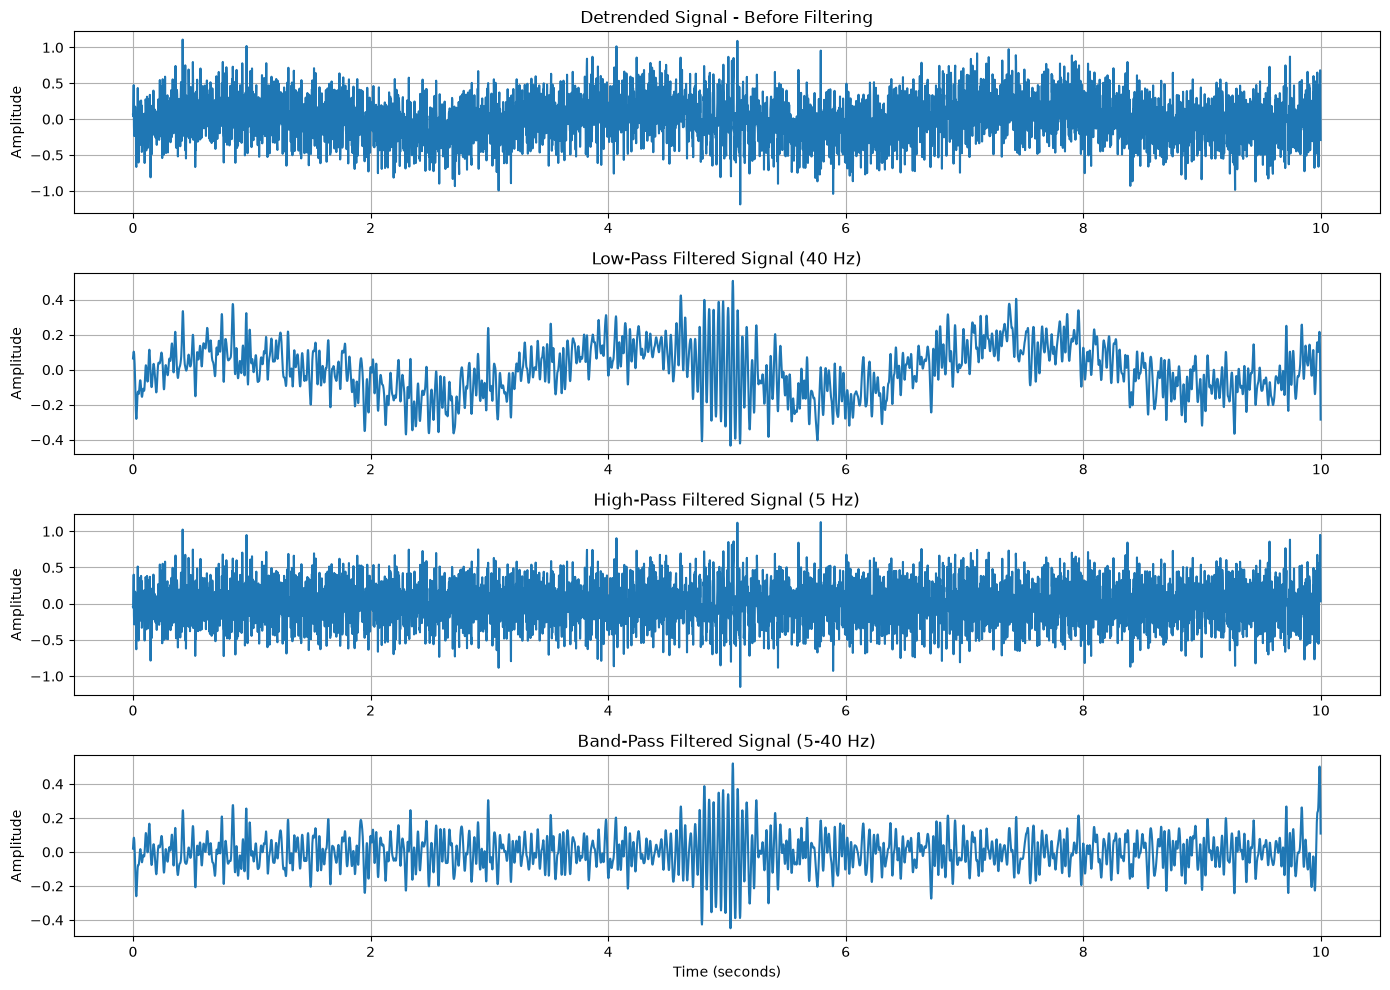

In [9]:

# Compare the results of different filters

plt.figure(figsize=(14, 10))

plt.subplot(4, 1, 1)
plt.plot(time, detrended_signal)
plt.title("Detrended Signal - Before Filtering")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(time, lowpass_signal)
plt.title("Low-Pass Filtered Signal (40 Hz)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(time, highpass_signal)
plt.title("High-Pass Filtered Signal (5 Hz)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(time, bandpass_signal)
plt.title("Band-Pass Filtered Signal (5-40 Hz)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()



## 8. Understanding Filter Frequency Response

A filter frequency response describes how strongly a filter allows or reduces different frequencies.

It helps us understand which frequencies pass through a filter and which frequencies are suppressed.

For our band-pass filter:

- Frequencies below 5 Hz should be strongly reduced.
- Frequencies between 5 Hz and 40 Hz should mostly pass.
- Frequencies above 40 Hz should be strongly reduced.

We can visualize this behavior using a frequency response graph.

This is useful because selecting a filter based only on its name or cutoff frequency is not enough. We should understand how it behaves across the frequency range.


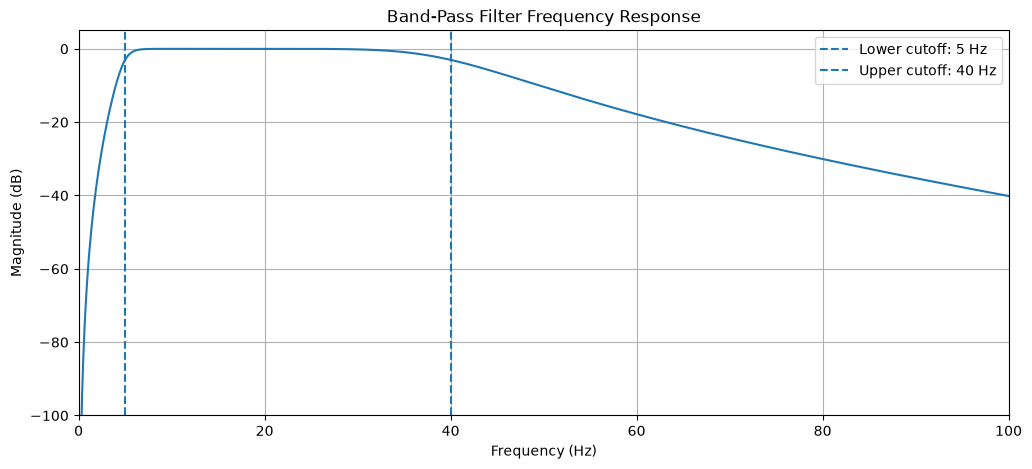

In [10]:

# Calculate the band-pass filter frequency response

frequencies_response, response = signal.sosfreqz(
    bandpass_sos,
    worN=2000,
    fs=sampling_rate
)

# Convert response magnitude into decibels

response_db = 20 * np.log10(
    np.maximum(np.abs(response), 1e-10)
)

# Plot the frequency response

plt.figure(figsize=(12, 5))

plt.plot(frequencies_response, response_db)

plt.title("Band-Pass Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")

plt.axvline(5, linestyle="--", label="Lower cutoff: 5 Hz")
plt.axvline(40, linestyle="--", label="Upper cutoff: 40 Hz")

plt.xlim(0, 100)
plt.ylim(-100, 5)

plt.grid(True)
plt.legend()
plt.show()



## 9. Evaluating Weak Event Preservation

One of the most important challenges in geophysical signal preprocessing is preserving weak events.

A filter may reduce unwanted noise, but it may also weaken or distort useful signal components.

This is particularly important for microseismic event detection because weak events may contain important information.

In our synthetic example, we already know the original event signal.

We can compare:

1. The original weak event.
2. The raw signal containing noise and interference.
3. The signal after band-pass filtering.

We will focus on the time interval around the synthetic event.

This comparison helps us understand whether the selected filter retains the event.

**Important:** A visually cleaner signal does not automatically mean better event detection. We must evaluate whether useful signal information has been preserved.


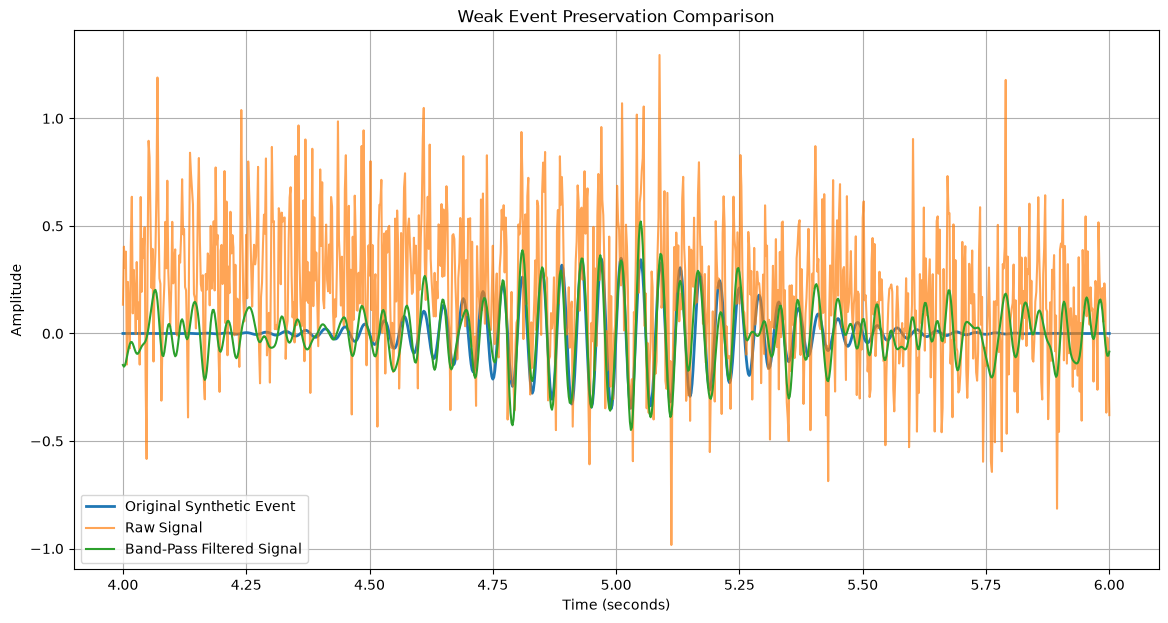

Event preservation comparison completed!


In [11]:

# Select the time interval around the synthetic event

event_region = (
    (time >= 4.0) &
    (time <= 6.0)
)

# Compare the original event and processed signals

plt.figure(figsize=(14, 7))

plt.plot(
    time[event_region],
    event_signal[event_region],
    label="Original Synthetic Event",
    linewidth=2
)

plt.plot(
    time[event_region],
    raw_signal[event_region],
    label="Raw Signal",
    alpha=0.7
)

plt.plot(
    time[event_region],
    bandpass_signal[event_region],
    label="Band-Pass Filtered Signal",
    linewidth=1.5
)

plt.title("Weak Event Preservation Comparison")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.grid(True)
plt.legend()
plt.show()

print("Event preservation comparison completed!")



## 10. Summary and Learning Outcomes

In this notebook, we explored several important geophysical signal preprocessing techniques using synthetic data.

We learned about:

1. Generating and inspecting synthetic geophysical signals.
2. Identifying baseline drift, interference, and random noise.
3. Handling missing and invalid values.
4. Removing the mean through demeaning.
5. Removing linear trends through detrending.
6. Applying Z-score normalization.
7. Understanding low-pass, high-pass, and band-pass filters.
8. Applying digital filters using SciPy.
9. Understanding filter frequency response.
10. Comparing signals before and after preprocessing.
11. Evaluating whether weak events are preserved.

These techniques provide an important foundation for preparing geophysical recordings for further analysis.

### Research Considerations

Preprocessing must be selected according to the characteristics of the data and the research objective.

A filter that works well for one dataset may not work well for another.

In GeoWaveAI, we will eventually investigate how preprocessing affects weak seismic and microseismic event detection using real recordings.

**Important:** All results in this notebook are based on synthetic educational signals. No real seismic or DAS dataset has been processed yet.
